## Notebook setup

In [8]:
%run "set_up_X_y.ipynb"

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


C:\Users\NM2.ZVLKND36\AppData\Local\Temp\ipykernel_32932\3376826814.py:1: DtypeWarning: Columns (23,24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/covid_engineered_dataset.csv")


## Random Forest

### Remove date col

In [9]:
X_train = X_train.drop(columns=["test_date", "corona_result", "age_60_and_above", "gender", "test_indication", "test_date_parsed"])
X_val = X_val.drop(columns=["test_date", "corona_result", "age_60_and_above", "gender", "test_indication", "test_date_parsed"])
X_test = X_test.drop(columns=["test_date", "corona_result", "age_60_and_above", "gender", "test_indication", "test_date_parsed"])

y_train_target = y_train["target"]
y_val_target = y_val["target"]
y_test_target = y_test["target"]

### Baseline - Create and train, predict, and evaluate a simple DTC

In [11]:
# Create model
rf_untuned = RandomForestClassifier(
    class_weight = "balanced",
    n_estimators=100,
    random_state=2,
    n_jobs=-1
)


rf_untuned.fit(X_train, y_train_target)

evaluate_model(
    rf_untuned,
    X_train,
    y_train_target,
    "UNTUNED DTC: TRAIN"
)

evaluate_model(
    rf_untuned,
    X_val,
    y_val_target,
    "UNTUNED DTC: VALIDATION"
)


UNTUNED DTC: TRAIN
Accuracy:          92.09%
Balanced accuracy: 86.35%
Precision:         38.48%
Recall:            79.91%
F1 score:          51.94%
ROC-AUC:           0.911

Confusion matrix:
[[168861  13144]
 [  2066   8220]]

UNTUNED DTC: VALIDATION
Accuracy:          91.97%
Balanced accuracy: 85.95%
Precision:         37.97%
Recall:            79.22%
F1 score:          51.34%
ROC-AUC:           0.911

Confusion matrix:
[[36149  2852]
 [  458  1746]]


### Grid search

In [22]:
param_grid_rf = {
    "n_estimators": [100, 300],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 10],
    "min_samples_leaf": [1, 5],
    "max_features": ["sqrt"],
    "class_weight": [None, "balanced"]
}

In [23]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=2
)

rf_search = RandomForestClassifier(
    random_state=2,
    n_jobs=-1
)

grid_rf = GridSearchCV(
    estimator=rf_search,
    param_grid=param_grid_rf,
    scoring={
        "roc_auc": "roc_auc",
        "f1": "f1",
        "recall": "recall",
        "precision": "precision",
        "balanced_accuracy": "balanced_accuracy"
    },
    refit="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

grid_rf.fit(X_train, y_train_target)

Fitting 3 folds for each of 48 candidates, totalling 144 fits


,estimator,RandomForestC...andom_state=2)
,param_grid,"{'class_weight': [None, 'balanced'], 'max_depth': [5, 10, ...], 'max_features': ['sqrt'], 'min_samples_leaf': [1, 5], ...}"
,scoring,"{'balanced_accuracy': 'balanced_accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall', ...}"
,n_jobs,-1
,refit,'roc_auc'
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,n_estimators,100


In [24]:
print("Best parameters:")
print(grid_rf.best_params_)

print(f"\nBest CV ROC-AUC: {grid_rf.best_score_:.3f}")

Best parameters:
{'class_weight': None, 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 100}

Best CV ROC-AUC: 0.909


In [25]:
rf_tuned = grid_rf.best_estimator_

evaluate_model(
    rf_tuned,
    X_train,
    y_train_target,
    "TUNED RF: TRAIN"
)

evaluate_model(
    rf_tuned,
    X_val,
    y_val_target,
    "TUNED RF: VALIDATION"
)


TUNED RF: TRAIN
Accuracy:          97.00%
Balanced accuracy: 78.50%
Precision:         80.54%
Recall:            57.79%
F1 score:          67.29%
ROC-AUC:           0.910

Confusion matrix:
[[180569   1436]
 [  4342   5944]]

TUNED RF: VALIDATION
Accuracy:          97.10%
Balanced accuracy: 78.95%
Precision:         82.03%
Recall:            58.62%
F1 score:          68.38%
ROC-AUC:           0.913

Confusion matrix:
[[38718   283]
 [  912  1292]]


In [27]:
evaluate_model(
    rf_tuned,
    X_train,
    y_train_target,
    "TUNED DTC: TRAIN"
)


TUNED DTC: TRAIN
Accuracy:          97.00%
Balanced accuracy: 78.50%
Precision:         80.54%
Recall:            57.79%
F1 score:          67.29%
ROC-AUC:           0.910

Confusion matrix:
[[180569   1436]
 [  4342   5944]]


### Run on test set

In [29]:
evaluate_model(
    rf_tuned,
    X_test,
    y_test_target,
    "FINAL TUNED DTC: TEST"
)


FINAL TUNED DTC: TEST
Accuracy:          96.93%
Balanced accuracy: 78.34%
Precision:         79.30%
Recall:            57.53%
F1 score:          66.68%
ROC-AUC:           0.904

Confusion matrix:
[[38671   331]
 [  936  1268]]


### ROC AUC

In [30]:
# Probability of positive class (1)
y_prob_val = rf_tuned.predict_proba(X_val)[:, 1]

# ROC-AUC score
roc_auc = roc_auc_score(y_val["target"], y_prob_val)

print(f"Validation ROC-AUC: {roc_auc:.3f}")

Validation ROC-AUC: 0.913


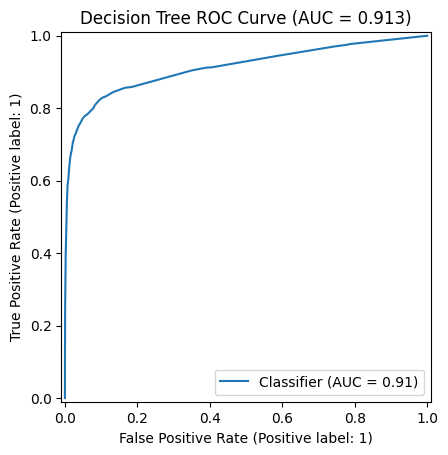

In [31]:
RocCurveDisplay.from_predictions(
    y_val["target"],
    y_prob_val
)

plt.title(f"Decision Tree ROC Curve (AUC = {roc_auc:.3f})")
plt.show()

### Find good threshold

In [38]:
# Probability of positive class
y_prob_val = rf_tuned.predict_proba(X_val)[:, 1]

for threshold in np.arange(0.1, 0.55, 0.05):

    y_pred = (y_prob_val >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_score(y_val_target, y_pred, zero_division=0):.2%} | "
        f"Recall: {recall_score(y_val_target, y_pred):.2%} | "
        f"F1: {f1_score(y_val_target, y_pred):.2%}"
    )

Threshold: 0.10 | Precision: 47.48% | Recall: 77.00% | F1: 58.74%
Threshold: 0.15 | Precision: 60.52% | Recall: 72.41% | F1: 65.94%
Threshold: 0.20 | Precision: 63.56% | Recall: 70.92% | F1: 67.04%
Threshold: 0.25 | Precision: 69.20% | Recall: 67.70% | F1: 68.44%
Threshold: 0.30 | Precision: 69.98% | Recall: 67.47% | F1: 68.70%
Threshold: 0.35 | Precision: 74.93% | Recall: 63.75% | F1: 68.89%
Threshold: 0.40 | Precision: 78.50% | Recall: 60.30% | F1: 68.21%
Threshold: 0.45 | Precision: 81.06% | Recall: 59.21% | F1: 68.43%
Threshold: 0.50 | Precision: 82.03% | Recall: 58.62% | F1: 68.38%


In [43]:
best_threshold = None
best_f1 = 0

for threshold in np.arange(0.05, 0.951, 0.01):

    y_pred = (y_prob_val >= threshold).astype(int)

    score = f1_score(y_val_target, y_pred)

    if score > best_f1:
        best_f1 = score
        best_threshold = threshold

print(f"Best threshold: {best_threshold:.2f}")
print(f"Best validation F1: {best_f1:.2%}")

Best threshold: 0.32
Best validation F1: 69.03%


In [48]:
# manual
best_threshold = 0.15

In [49]:
y_pred_val = (y_prob_val >= best_threshold).astype(int)

print(f"Threshold:         {best_threshold:.2f}")
print(f"Accuracy:          {accuracy_score(y_val_target, y_pred_val):.2%}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_val_target, y_pred_val):.2%}")
print(f"Precision:         {precision_score(y_val_target, y_pred_val, zero_division=0):.2%}")
print(f"Recall:            {recall_score(y_val_target, y_pred_val, zero_division=0):.2%}")
print(f"F1 score:          {f1_score(y_val_target, y_pred_val, zero_division=0):.2%}")
print(f"ROC-AUC:           {roc_auc_score(y_val_target, y_prob_val):.3f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_val_target, y_pred_val))

Threshold:         0.15
Accuracy:          96.00%
Balanced accuracy: 84.87%
Precision:         60.52%
Recall:            72.41%
F1 score:          65.94%
ROC-AUC:           0.913

Confusion matrix:
[[37960  1041]
 [  608  1596]]
